# 03 · Baseline, modelos e validação — Occasion Prediction

Passos 2, 3, 5, 6 e 7 da aula: **separar os dados → baseline → modelos → escolher features → avaliar**.

**Pergunta:** dado um contexto (quem, onde, quando, em que refeição), qual a probabilidade de a ocasião ter pizza?
A saída é o **Occasion Score** = P(pizza | contexto).

In [26]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import TARGET, colunas, derivar, preprocessador

AZUL, LARANJA, CINZA, VERDE = "#2a78d6", "#eb6834", "#52514e", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e2",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelcolor": CINZA, "xtick.color": CINZA, "ytick.color": CINZA,
})
SEED = 42

base = pd.read_parquet(ROOT / "data" / "processed" / "base_modelagem.parquet")
base = base[base["refeicao"] != "indefinido"].reset_index(drop=True)  # sem contexto declarado
base = derivar(base)  # mesmas derivações que a API vai usar
print(base.shape, "| taxa de pizza:", f"{base[TARGET].mean():.3%}")

(347985, 37) | taxa de pizza: 0.489%


## 1. Separar os dados (Passo 2)

**Sem data na POF**, não dá para fazer o corte temporal que a aula recomenda. Substituímos por dois cortes que medem generalização:

1. **Por domicílio** (principal): a mesma família nunca aparece em treino e teste. Sem isso, o modelo "decoraria" pessoas — cada pessoa tem várias ocasiões em 2 dias, e uma família tende a comer igual.
2. **Por região** (robustez): treina em 4 regiões e testa na 5ª, que nunca viu. É o teste "o modelo funciona num território novo?" — o TAPI cita splits por região como medida de generalização.

Estrutura:
- **Teste (20% dos domicílios):** separado agora e **só aberto no final**.
- **Desenvolvimento (80%):** validação cruzada em 5 dobras por domicílio, para comparar modelos e features.

In [27]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_dev, idx_teste = next(gss.split(base, base[TARGET], groups=base["id_domicilio"]))
dev, teste = base.iloc[idx_dev].reset_index(drop=True), base.iloc[idx_teste].reset_index(drop=True)
assert not set(dev.id_domicilio) & set(teste.id_domicilio)
print(f"dev: {len(dev):,} ocasiões ({dev[TARGET].sum()} pizzas) | teste: {len(teste):,} ({teste[TARGET].sum()} pizzas)")

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dobras = list(cv.split(dev, dev[TARGET], groups=dev["id_domicilio"]))

dev: 277,978 ocasiões (1331 pizzas) | teste: 70,007 (371 pizzas)


## 2. Métricas (Passo 7)

A pizza aparece em ~0,5% das ocasiões. Um modelo que diz sempre "não" acerta 99,5% — **acurácia não serve**.

| Métrica | O que mede | Por que usar |
|---|---|---|
| **PR-AUC** (principal) | qualidade do ranking focada na classe rara | um palpite aleatório tem PR-AUC = taxa base (~0,005) |
| ROC-AUC | ranking geral | complementar; parece otimista com classe rara |
| **Lift no top 10%** | quantas vezes mais pizza há nos 10% contextos de maior score do que na média | é a leitura de negócio: "se eu ativar só nos 10% melhores contextos, concentro X vezes mais ocasiões" |
| Recall no top 10% | % de todas as pizzas que estão nesses 10% | quanto da ocasião a ativação cobre |
| Brier | erro da probabilidade | verifica a **calibração** do score |

In [28]:
def metricas(y, p, top=0.10):
    y, p = np.asarray(y), np.asarray(p)
    # top 10% exato por ranking (empates desfeitos ao acaso, para scores binários como a regra fixa)
    rng = np.random.default_rng(0)
    ordem = np.lexsort((rng.random(len(p)), -p))
    sel = np.zeros(len(p), dtype=bool)
    sel[ordem[: int(round(top * len(p)))]] = True
    return {
        "PR-AUC": average_precision_score(y, p),
        "ROC-AUC": roc_auc_score(y, p),
        "lift_top10": y[sel].mean() / y.mean(),
        "recall_top10": y[sel].sum() / y.sum(),
        "brier": brier_score_loss(y, p),
    }


def avaliar_cv(fabrica, df, dobras, familias=None):
    """Treina em 4 dobras e prevê a 5ª; devolve a previsão 'fora da dobra' (OOF) para cada linha."""
    oof = np.zeros(len(df))
    for tr, va in dobras:
        modelo = fabrica()
        modelo.fit(df.iloc[tr], df[TARGET].iloc[tr])
        oof[va] = modelo.predict_proba(df.iloc[va])[:, 1]
    return oof

## 3. Baseline (Passo 3) — "sem Machine Learning"

Exigido pelo TAPI: **frequência histórica de pizza por dia da semana × período do dia**, calculada só no treino.
É uma tabela de consulta: para um contexto novo, o score é a taxa histórica daquela célula.

Também testamos a **regra fixa** citada no TAPI: "ativar de sexta a domingo à noite" (score 1 ou 0).

In [29]:
class BaselineFrequencia:
    """Taxa histórica de pizza por combinação de colunas (com suavização para células pequenas)."""

    def __init__(self, chaves=("dia_semana", "periodo"), suavizacao=50):
        self.chaves, self.k = list(chaves), suavizacao

    def fit(self, X, y):
        d = X[self.chaves].assign(y=np.asarray(y))
        self.media_ = d["y"].mean()
        g = d.groupby(self.chaves)["y"].agg(["sum", "count"])
        # média suavizada: células com poucos casos puxam para a média geral
        self.tabela_ = (g["sum"] + self.k * self.media_) / (g["count"] + self.k)
        return self

    def predict_proba(self, X):
        idx = pd.MultiIndex.from_frame(X[self.chaves])
        p = self.tabela_.reindex(idx).fillna(self.media_).to_numpy()
        return np.c_[1 - p, p]


class RegraFixa:
    """Sexta a domingo, à noite = 1; caso contrário 0."""

    def fit(self, X, y):
        return self

    def predict_proba(self, X):
        p = ((X["fim_de_semana"] == 1) & (X["periodo"] == "noite")).astype(float).to_numpy()
        return np.c_[1 - p, p]


resultados = {}
oofs = {}
for nome, fab in {
    "Regra fixa (sex-dom noite)": RegraFixa,
    "Baseline dia × período": BaselineFrequencia,
}.items():
    oofs[nome] = avaliar_cv(fab, dev, dobras)
    resultados[nome] = metricas(dev[TARGET], oofs[nome])
pd.DataFrame(resultados).T.style.format("{:.3f}")

,PR-AUC,ROC-AUC,lift_top10,recall_top10,brier
Regra fixa (sex-dom noite),0.012,0.670,4.373,0.437,0.092
Baseline dia × período,0.018,0.802,4.410,0.441,0.005


## 4. Modelos candidatos

- **Regressão Logística:** linear, simples, coeficientes interpretáveis. Precisa de variáveis padronizadas.
- **Random Forest:** muitas árvores **independentes**, cada uma treinada num sorteio diferente das refeições e das features (**bagging**); a previsão é a **média** das árvores. Reduz a variância de árvores profundas.
- **LightGBM:** árvores de decisão em sequência (gradient boosting). Captura **interações** (ex.: "noite" só importa muito se for "fim de semana" e "renda alta") — exatamente o que o TAPI diz que regras fixas não capturam.

Ambos usam o **mesmo pré-processamento** (`src/features.py`) dentro de um `Pipeline`: a imputação e a padronização são ajustadas **só no treino de cada dobra** (evita vazamento).

In [30]:
TODAS = ["contexto", "pessoa", "territorio"]

def fab_logistica(familias=TODAS):
    return lambda: Pipeline([
        ("prep", preprocessador(familias, escalar=True)),
        ("modelo", LogisticRegression(max_iter=2000, C=0.5)),
    ])


def fab_lgbm(familias=TODAS, excluir=()):
    return lambda: Pipeline([
        ("prep", preprocessador(familias, escalar=False, excluir=excluir)),
        ("modelo", LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15,
                                  min_child_samples=200, subsample=0.8, subsample_freq=1,
                                  colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED,
                                  verbose=-1)),
    ])


def fab_rf(familias=TODAS):
    # min_samples_leaf alto: cada folha precisa de 100 refeições (evita decorar)
    return lambda: Pipeline([
        ("prep", preprocessador(familias, escalar=False)),
        ("modelo", RandomForestClassifier(n_estimators=300, min_samples_leaf=100, max_features="sqrt",
                                          n_jobs=-1, random_state=SEED)),
    ])


for nome, fab in {"Regressão Logística": fab_logistica(), "Random Forest": fab_rf(),
                  "LightGBM": fab_lgbm()}.items():
    oofs[nome] = avaliar_cv(fab, dev, dobras)
    resultados[nome] = metricas(dev[TARGET], oofs[nome])

tabela = pd.DataFrame(resultados).T
tabela.style.format("{:.3f}").highlight_max(subset=["PR-AUC", "ROC-AUC", "lift_top10", "recall_top10"],
                                         props="font-weight: bold; background-color: #cde2fb; color: #0b0b0b")

,PR-AUC,ROC-AUC,lift_top10,recall_top10,brier
Regra fixa (sex-dom noite),0.012,0.670,4.373,0.437,0.092
Baseline dia × período,0.018,0.802,4.410,0.441,0.005
Regressão Logística,0.073,0.891,6.987,0.699,0.005
Random Forest,0.076,0.891,6.754,0.675,0.005
LightGBM,0.080,0.893,6.897,0.690,0.005


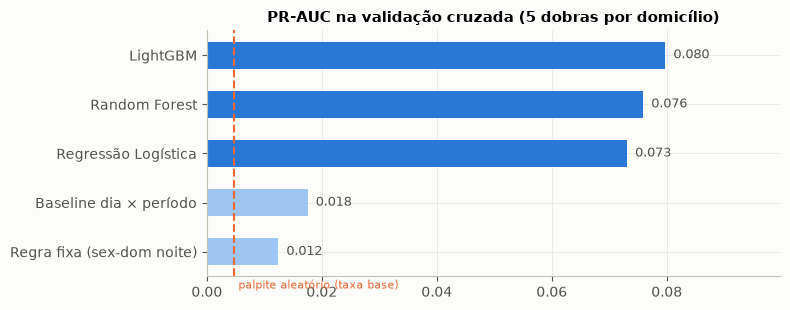

In [31]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ordem = tabela["PR-AUC"].sort_values()
cores = [AZUL if n in ("LightGBM", "Regressão Logística", "Random Forest") else "#9ec5f4" for n in ordem.index]
ax.barh(ordem.index, ordem.values, color=cores, height=0.55)
ax.axvline(dev[TARGET].mean(), color=LARANJA, lw=1.5, ls="--")
ax.text(dev[TARGET].mean(), -0.75, " palpite aleatório (taxa base)", color=LARANJA, fontsize=8)
for i, v in enumerate(ordem.values):
    ax.text(v, i, f"  {v:.3f}", va="center", fontsize=9, color=CINZA)
ax.set_title("PR-AUC na validação cruzada (5 dobras por domicílio)")
ax.set_xlim(0, ordem.max() * 1.25)
plt.tight_layout()
plt.show()

**Bagging × boosting na prática:** o Random Forest (árvores independentes, média) e o LightGBM (árvores em sequência, soma) usam as mesmas features. A comparação mostra se corrigir erros em sequência rende mais do que fazer a média de árvores independentes.

**Leitura:** se os modelos superam o baseline dia × período, eles aprenderam algo **além de "sexta à noite é bom para pizza"** — que é exatamente a pergunta do TAPI.

## 5. Ablação por família de features (Passo 5) — "misturar features de lugares"

A prova mais direta de que uma fonte de dados agrega valor: **adicionar uma família de cada vez e medir o ganho**.
- só **contexto** (quando/onde come) → + **pessoa** (POF Morador) → + **território** (SIDRA + OSM)

In [32]:
ablacao = {}
for fams in [["contexto"], ["contexto", "pessoa"], ["contexto", "pessoa", "territorio"]]:
    nome = " + ".join(fams)
    p = avaliar_cv(fab_lgbm(fams), dev, dobras)
    ablacao[nome] = metricas(dev[TARGET], p)
abl = pd.DataFrame(ablacao).T
abl["ganho_PR-AUC_vs_anterior"] = abl["PR-AUC"].diff()
abl.style.format("{:.3f}", na_rep="—")

,PR-AUC,ROC-AUC,lift_top10,recall_top10,brier,ganho_PR-AUC_vs_anterior
contexto,0.072,0.867,6.033,0.603,0.005,—
contexto + pessoa,0.081,0.888,6.859,0.686,0.005,0.009
contexto + pessoa + territorio,0.080,0.893,6.897,0.690,0.005,-0.001


Cada linha mostra **quanto aquela fonte de dados acrescenta**. Esse é o argumento para justificar, no vídeo e no README, por que cada fonte foi cruzada.

## 6. Generalização para regiões novas (deixa-uma-região-fora)

Treina com 4 regiões, testa na 5ª, que o modelo **nunca viu**. Aqui `regiao` sai das features: o modelo não pode usar o nome de uma região que nunca viu.

Comparamos **três versões** em cada região de teste:
- **Baseline dia × período** (a régua);
- **LightGBM sem território**: só contexto + pessoa; o modelo não sabe nada sobre o lugar;
- **LightGBM com território**: + pizzarias por 100 mil hab., renda média e população da UF.

A diferença entre as duas versões do LightGBM é uma **ablação dentro do teste de regiões**: mostra se o território ajuda o modelo a funcionar num lugar novo.

In [33]:
TERRITORIO_UF = ("pizzarias_100k", "renda_media_pc_uf", "log_populacao_uf")
versoes = {
    "Baseline dia × período": BaselineFrequencia,
    "LightGBM sem território": fab_lgbm(excluir=("regiao",) + TERRITORIO_UF),
    "LightGBM com território": fab_lgbm(excluir=("regiao",)),
}
linhas = []
for r in dev["regiao"].unique():
    tr, va = dev[dev.regiao != r], dev[dev.regiao == r]
    for nome, fab in versoes.items():
        m = fab()
        m.fit(tr, tr[TARGET])
        p = m.predict_proba(va)[:, 1]
        linhas.append({"regiao_teste": r, "modelo": nome, **metricas(va[TARGET], p)})
loro = pd.DataFrame(linhas)
tab_loro = loro.pivot(index="regiao_teste", columns="modelo", values="PR-AUC")[list(versoes)]
tab_loro["ganho do território"] = tab_loro["LightGBM com território"] - tab_loro["LightGBM sem território"]
tab_loro.loc["MÉDIA"] = tab_loro.mean()
tab_loro.style.format("{:+.3f}", subset=["ganho do território"]).format(
    "{:.3f}", subset=list(versoes))

modelo,Baseline dia × período,LightGBM sem território,LightGBM com território,ganho do território
regiao_teste,,,,
Centro-Oeste,0.021,0.083,0.084,+0.002
Nordeste,0.014,0.098,0.102,+0.005
Norte,0.013,0.103,0.113,+0.011
Sudeste,0.024,0.098,0.107,+0.009
Sul,0.023,0.058,0.057,-0.002
MÉDIA,0.019,0.088,0.093,+0.005


**Leitura:**
- se as duas versões do LightGBM vencem o baseline em (quase) todas as regiões, o modelo **generaliza** para territórios novos;
- se **ganho do território** é positivo, as features territoriais ajudam o modelo num lugar que ele nunca viu;
- se é ≈ 0, o território não melhora a previsão — e a justificativa para mantê-lo passa a ser o Mapa de Oportunidade e o Decision Engine, que dependem dele.

## 7. Calibração do score

O Occasion Score deve ser uma **probabilidade honesta**: entre contextos com score 2%, ~2% devem ter pizza.
Comparamos a previsão média com a frequência observada em faixas de score (curva de calibração).

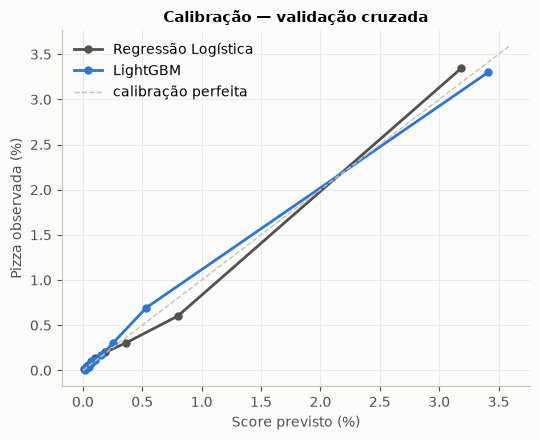

Brier de um palpite constante (taxa base): 0.00477


In [34]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for nome, cor in [("Regressão Logística", CINZA), ("LightGBM", AZUL)]:
    fr, mp = calibration_curve(dev[TARGET], oofs[nome], n_bins=10, strategy="quantile")
    ax.plot(mp * 100, fr * 100, marker="o", ms=5, lw=2, color=cor, label=nome)
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], color="#c3c2b7", ls="--", lw=1, label="calibração perfeita")
ax.set_xlabel("Score previsto (%)")
ax.set_ylabel("Pizza observada (%)")
ax.set_title("Calibração — validação cruzada")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print("Brier de um palpite constante (taxa base):", round(brier_score_loss(dev[TARGET], np.full(len(dev), dev[TARGET].mean())), 5))

Como **não usamos peso de classe** no treino, as probabilidades do LightGBM já saem próximas da frequência real — não precisamos de uma etapa extra de calibração (a aula mostrou que o peso de classe infla as probabilidades).

## 8. Do score à decisão: limiar e classificação

O Decision Engine precisa de uma classificação simples. Em vez de um limiar arbitrário de 0,5 (que nunca seria atingido com 0,5% de taxa base), usamos o **lift**: quantas vezes o contexto está acima da média.

| Classe | Regra | Leitura |
|---|---|---|
| **alta** | score ≥ limiar_alta (top ~10% dos contextos na validação) | priorizar ativação |
| **media** | score ≥ taxa base | ativação seletiva |
| **baixa** | score < taxa base | não priorizar |

**Custo dos erros:** um falso positivo gasta uma ativação num contexto pouco relevante (barato — ex.: um push); um falso negativo perde uma ocasião (mais caro). Por isso o corte "alta" é generoso (top 10%), privilegiando **recall**.

In [35]:
p_lgb = oofs["LightGBM"]
taxa_base = dev[TARGET].mean()
limiar_alta = float(np.quantile(p_lgb, 0.90))
classe = np.where(p_lgb >= limiar_alta, "alta", np.where(p_lgb >= taxa_base, "media", "baixa"))
tab_cls = (pd.DataFrame({"classe": classe, "y": dev[TARGET]})
           .groupby("classe")["y"].agg(contextos="size", pizzas="sum", taxa="mean"))
tab_cls["% das pizzas"] = tab_cls["pizzas"] / tab_cls["pizzas"].sum()
tab_cls["lift"] = tab_cls["taxa"] / taxa_base
print(f"taxa base = {taxa_base:.3%} | limiar 'alta' = {limiar_alta:.3%}")
tab_cls.loc[["alta", "media", "baixa"]].style.format({"taxa": "{:.2%}", "% das pizzas": "{:.1%}", "lift": "{:.1f}×"})

taxa base = 0.479% | limiar 'alta' = 0.882%


,contextos,pizzas,taxa,% das pizzas,lift
classe,,,,,
alta,27798,918,3.30%,69.0%,6.9×
media,15326,133,0.87%,10.0%,1.8×
baixa,234854,280,0.12%,21.0%,0.2×


In [36]:
cm = confusion_matrix(dev[TARGET], (p_lgb >= limiar_alta).astype(int))
pd.DataFrame(cm, index=["real: sem pizza", "real: pizza"], columns=["prev: não-alta", "prev: alta"])

,prev: não-alta,prev: alta
real: sem pizza,249767,26880
real: pizza,413,918


## 9. Avaliação final no teste (aberto só agora)

Treinamos o modelo escolhido com **todo o desenvolvimento** e avaliamos **uma única vez** no teste.

In [37]:
modelos_finais = {"Baseline dia × período": BaselineFrequencia(), "Regressão Logística": fab_logistica()(),
                  "Random Forest": fab_rf()(), "LightGBM": fab_lgbm()()}
final_teste = {}
p_teste = {}
for nome, m in modelos_finais.items():
    m.fit(dev, dev[TARGET])
    p_teste[nome] = m.predict_proba(teste)[:, 1]
    final_teste[nome] = metricas(teste[TARGET], p_teste[nome])
pd.DataFrame(final_teste).T.style.format("{:.3f}")

,PR-AUC,ROC-AUC,lift_top10,recall_top10,brier
Baseline dia × período,0.019,0.806,4.016,0.402,0.005
Regressão Logística,0.074,0.874,6.711,0.671,0.005
Random Forest,0.086,0.877,6.792,0.679,0.005
LightGBM,0.084,0.886,6.819,0.682,0.005


## 10. Análise por segmento (no teste)

Um bom resultado global pode esconder segmentos em que o modelo vai mal.

In [38]:
teste_av = teste.assign(p=p_teste["LightGBM"], p_base=p_teste["Baseline dia × período"])
seg_rows = []
for seg in ["periodo", "regiao", "classe_renda", "em_casa", "fim_de_semana"]:
    for v, g in teste_av.groupby(seg, observed=True):
        if g[TARGET].sum() < 15:
            continue
        seg_rows.append({"segmento": seg, "valor": v, "pizzas": int(g[TARGET].sum()),
                         "PR-AUC LightGBM": average_precision_score(g[TARGET], g["p"]),
                         "PR-AUC baseline": average_precision_score(g[TARGET], g["p_base"]),
                         "taxa base": g[TARGET].mean()})
pd.DataFrame(seg_rows).style.format({"PR-AUC LightGBM": "{:.3f}", "PR-AUC baseline": "{:.3f}", "taxa base": "{:.3%}"})

,segmento,valor,pizzas,PR-AUC LightGBM,PR-AUC baseline,taxa base
0,periodo,almoco,15,0.002,0.001,0.074%
1,periodo,manha,15,0.002,0.001,0.085%
2,periodo,noite,293,0.095,0.021,1.493%
3,periodo,tarde,34,0.023,0.003,0.338%
4,regiao,Centro-Oeste,64,0.090,0.038,0.738%
5,regiao,Nordeste,116,0.155,0.022,0.444%
6,regiao,Norte,53,0.090,0.017,0.554%
7,regiao,Sudeste,65,0.073,0.012,0.396%
8,regiao,Sul,73,0.049,0.019,0.792%
9,classe_renda,E,30,0.078,0.007,0.207%


## 10b. Análise de erros — onde o modelo falha?

Métricas dizem **quanto** o modelo erra; a análise de erros diz **em quê**. Usamos o **teste** (famílias que o modelo nunca viu) e o corte da classe **alta** (seção 8). Cada ocasião cai em um de 4 grupos:

| | Modelo disse "alta" | Modelo disse "não alta" |
|---|---|---|
| **Teve pizza** | **VP** — verdadeiro positivo (acertou) | **FN** — falso negativo (*perdeu a ocasião*) |
| **Não teve pizza** | **FP** — falso positivo (*ativação à toa*) | **VN** — verdadeiro negativo |

Perguntas:
1. **Que pizzas o modelo perde (FN)?** Comparamos o perfil das pizzas perdidas com o das pizzas encontradas (VP).
2. **Onde o modelo se engana para mais (FP)?** Que contextos recebem score alto sem ter pizza?

> Aqui podemos olhar qualquer coluna, inclusive as que o modelo não usa (ex.: se teve refrigerante): é **diagnóstico depois da previsão**, não feature.

In [39]:
av = teste.assign(p=p_teste["LightGBM"])
av["alta"] = av["p"] >= limiar_alta
av["tipo"] = np.select(
    [(av[TARGET] == 1) & av["alta"], (av[TARGET] == 1) & ~av["alta"], (av[TARGET] == 0) & av["alta"]],
    ["VP", "FN", "FP"], default="VN")
contagem = av["tipo"].value_counts().reindex(["VP", "FN", "FP", "VN"]).rename("ocasiões").to_frame()
contagem["leitura"] = ["pizzas encontradas", "pizzas perdidas", "ativações sem pizza", "corretamente ignoradas"]
contagem

,ocasiões,leitura
tipo,,
VP,252,pizzas encontradas
FN,119,pizzas perdidas
FP,6720,ativações sem pizza
VN,62916,corretamente ignoradas


### Que pizzas o modelo perde? (FN × VP)

Para cada característica, comparamos **como se distribuem** as pizzas perdidas (FN) e as encontradas (VP). Onde a coluna **FN** é bem maior que a **VP**, está o tipo de pizza que o modelo não enxerga.

In [40]:
pz = av[av[TARGET] == 1]
linhas = []
for col in ["refeicao", "periodo", "local", "fim_de_semana", "classe_renda", "regiao"]:
    dist = pd.crosstab(pz[col], pz["tipo"], normalize="columns")
    for valor, r in dist.iterrows():
        linhas.append({"característica": col, "valor": valor, "% das pizzas perdidas (FN)": r.get("FN", 0),
                       "% das pizzas encontradas (VP)": r.get("VP", 0)})
perfil_fn = pd.DataFrame(linhas)
perfil_fn["diferença"] = perfil_fn["% das pizzas perdidas (FN)"] - perfil_fn["% das pizzas encontradas (VP)"]
(perfil_fn.sort_values("diferença", ascending=False).head(10)
 .style.format({"% das pizzas perdidas (FN)": "{:.0%}", "% das pizzas encontradas (VP)": "{:.0%}", "diferença": "{:+.0%}"}))

,característica,valor,% das pizzas perdidas (FN),% das pizzas encontradas (VP),diferença
10,periodo,tarde,25%,2%,+24%
16,fim_de_semana,0,69%,46%,+22%
4,refeicao,lanche,26%,10%,+17%
11,local,casa,81%,66%,+15%
0,refeicao,almoco,13%,0%,+13%
8,periodo,manha,13%,0%,+13%
6,periodo,almoco,13%,0%,+13%
5,refeicao,outra,12%,0%,+12%
1,refeicao,cafe,11%,0%,+11%
18,classe_renda,E,15%,5%,+10%


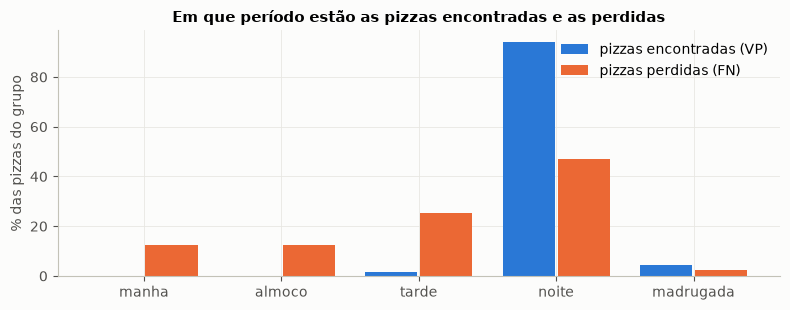

Das pizzas perdidas, 67% ficaram até abaixo da média Brasil (classe 'baixa').


In [41]:
ordem_per = ["manha", "almoco", "tarde", "noite", "madrugada"]
dist_per = pd.crosstab(pz["periodo"], pz["tipo"], normalize="columns").reindex(ordem_per)[["VP", "FN"]] * 100
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(ordem_per))
ax.bar(x - 0.2, dist_per["VP"], width=0.38, color=AZUL, label="pizzas encontradas (VP)")
ax.bar(x + 0.2, dist_per["FN"], width=0.38, color=LARANJA, label="pizzas perdidas (FN)")
ax.set_xticks(x, ordem_per)
ax.set_ylabel("% das pizzas do grupo")
ax.set_title("Em que período estão as pizzas encontradas e as perdidas")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print(f"Das pizzas perdidas, {(pz.loc[pz.tipo == 'FN', 'p'] < taxa_base).mean():.0%} ficaram até abaixo da média Brasil (classe 'baixa').")

### Os erros mais graves: pizzas com o menor score
Repare na coluna `id_domicilio`: às vezes **a mesma família** aparece várias vezes — um evento único da casa (uma festa, sobra de pizza) gera vários erros de uma vez.

In [42]:
cols_err = ["id_domicilio", "dia_semana", "hora", "refeicao", "local", "idade", "renda_pc", "n_moradores", "regiao", "p"]
av[av.tipo == "FN"].sort_values("p")[cols_err].head(10).style.format({"p": "{:.3%}", "renda_pc": "R$ {:,.0f}", "hora": "{:.0f}h"})

,id_domicilio,dia_semana,hora,refeicao,local,idade,renda_pc,n_moradores,regiao,p
21913,250011676_16,Quinta-Feira,13h,almoco,casa,13,R$ 297,4,Nordeste,0.014%
21892,250011676_16,Quinta-Feira,13h,almoco,casa,43,R$ 297,4,Nordeste,0.016%
21899,250011676_16,Quinta-Feira,13h,almoco,casa,36,R$ 297,4,Nordeste,0.016%
21906,250011676_16,Quinta-Feira,13h,almoco,casa,18,R$ 297,4,Nordeste,0.016%
65983,510051260_16,Segunda-Feira,8h,cafe,casa,43,R$ nan,3,Centro-Oeste,0.028%
65979,510051260_16,Segunda-Feira,8h,cafe,casa,56,"R$ 2,220",3,Centro-Oeste,0.029%
65418,510038622_9,Segunda-Feira,12h,almoco,casa,17,R$ 992,4,Centro-Oeste,0.031%
17053,230041375_3,Quarta-Feira,7h,cafe,casa,10,R$ 430,3,Nordeste,0.048%
62975,500028448_5,Quarta-Feira,16h,outra,casa,37,R$ 596,4,Centro-Oeste,0.051%
5209,150016482_10,Segunda-Feira,9h,cafe,casa,27,"R$ 1,513",4,Norte,0.052%


### Onde o modelo se engana para mais? (FP)
Os falsos positivos são contextos com **cara de pizza** que acabaram sem pizza. Que contextos são esses?

In [43]:
fp = av[av.tipo == "FP"]
resumo_fp = pd.DataFrame({
    "refeição mais comum": [fp["refeicao"].value_counts(normalize=True).head(2).round(2).to_dict()],
    "local mais comum": [fp["local"].value_counts(normalize=True).head(2).round(2).to_dict()],
    "período mais comum": [fp["periodo"].value_counts(normalize=True).head(2).round(2).to_dict()],
}).T.rename(columns={0: "FP"})
display(resumo_fp)
print(f"Teve refrigerante: {fp['tem_refri'].mean():.1%} dos falsos positivos x {av.loc[av.tipo == 'VN', 'tem_refri'].mean():.1%} dos verdadeiros negativos")

,FP
refeição mais comum,"{'jantar': 0.82, 'lanche': 0.15}"
local mais comum,"{'casa': 0.83, 'fora_outros': 0.1}"
período mais comum,"{'noite': 0.89, 'tarde': 0.06}"


Teve refrigerante: 8.5% dos falsos positivos x 2.9% dos verdadeiros negativos


### Conclusões da análise de erros

**Pizzas que o modelo perde (FN):** são principalmente as pizzas **"fora de hora"** — no **almoço, café da manhã e tarde**, em **dias úteis** e **em casa**, com peso maior das classes de renda mais baixas. O modelo aprendeu que pizza é coisa da noite; ocasiões atípicas (sobra de pizza no dia seguinte, festa em casa, lanche da tarde) ficam com score baixo. Alguns erros vêm de **uma mesma família** num mesmo evento.

**O que isso significa para o negócio:** o sistema é bom para o **núcleo da ocasião** (noite, jantar, fim de semana, fora de casa), que é onde está a maior parte das pizzas. Pizzas fora de hora são poucas e difíceis de prever — e também são as de **menor valor para ativação**, porque não seguem um padrão que a Ambev consiga antecipar.

**Ativações "sem pizza" (FP):** são quase todas **jantares em casa, à noite** — contextos com cara de pizza em que a pessoa comeu outra coisa. Eles têm **mais refrigerante** que a média: são ocasiões em que um refrigerante já acompanha a refeição. Ou seja, o custo de um falso positivo é baixo: a ativação cai num momento **parecido** com a ocasião-alvo (e o TAPI considera falso positivo um erro barato).

**Limitação:** a POF tem a pergunta "foi um dia atípico?" (`DIA_ATIPICO`), que poderia confirmar a hipótese das pizzas fora de hora. Ela não é usada como feature (é respondida depois), mas poderia entrar numa análise de erros futura.

## 11. Salvar o modelo final

O modelo final é treinado com **dev + teste** (todos os dados) depois da avaliação, como é prática comum; as métricas reportadas são as do teste acima.
Salvamos junto os **metadados** que a API vai devolver em `model_metadata`.

In [44]:
modelo_final = fab_lgbm()()
modelo_final.fit(base, base[TARGET])
(ROOT / "models").mkdir(exist_ok=True)
joblib.dump(modelo_final, ROOT / "models" / "occasion_model.joblib")

cat, num = colunas(TODAS)
meta = {
    "modelo": "LightGBM (sklearn Pipeline)",
    "versao": "1.0.0",
    "target": "y_pizza — ocasião de consumo com pizza (POF 2017-2018)",
    "unidade": "pessoa × dia × refeição",
    "features_categoricas": cat,
    "features_numericas": num,
    "taxa_base": float(base[TARGET].mean()),
    "limiar_alta": limiar_alta,
    "validacao": "5 dobras agrupadas por domicílio + teste de 20% dos domicílios + deixa-uma-região-fora",
    "metricas_teste": {k: round(float(v), 4) for k, v in final_teste["LightGBM"].items()},
    "metricas_teste_baseline": {k: round(float(v), 4) for k, v in final_teste["Baseline dia × período"].items()},
}
(ROOT / "models" / "metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
meta

{'modelo': 'LightGBM (sklearn Pipeline)',
 'versao': '1.0.0',
 'target': 'y_pizza — ocasião de consumo com pizza (POF 2017-2018)',
 'unidade': 'pessoa × dia × refeição',
 'features_categoricas': ['dia_semana',
  'periodo',
  'dia_periodo',
  'refeicao',
  'local',
  'sexo',
  'regiao'],
 'features_numericas': ['hora',
  'fim_de_semana',
  'em_casa',
  'idade',
  'anos_estudo',
  'log_renda_pc',
  'n_moradores',
  'n_criancas',
  'n_adolescentes',
  'tem_crianca',
  'urbano',
  'pizzarias_100k',
  'renda_media_pc_uf',
  'log_populacao_uf'],
 'taxa_base': 0.004891015417331207,
 'limiar_alta': 0.008823839125901616,
 'validacao': '5 dobras agrupadas por domicílio + teste de 20% dos domicílios + deixa-uma-região-fora',
 'metricas_teste': {'PR-AUC': 0.0837,
  'ROC-AUC': 0.8863,
  'lift_top10': 6.8191,
  'recall_top10': 0.6819,
  'brier': 0.0051},
 'metricas_teste_baseline': {'PR-AUC': 0.019,
  'ROC-AUC': 0.806,
  'lift_top10': 4.016,
  'recall_top10': 0.4016,
  'brier': 0.0052}}

## Resumo

- **Validação:** por domicílio (sem família repetida entre treino e teste) + teste por região nova. Validação temporal impossível (POF sem data) — documentado.
- **Baseline vs modelo:** compare as tabelas das seções 4 e 9. O ganho do LightGBM sobre o baseline mostra o que o modelo aprende **além de dia × período**.
- **Ablação:** mostra quanto cada fonte (POF Morador, SIDRA, OSM) agrega.
- **Score → decisão:** classes alta/média/baixa por lift, com o corte "alta" no top 10% (privilegia recall).
- **Próximo:** notebook 04 — SHAP (por que o score é alto?), clusters de contexto (jobs) e as métricas de Guaraná para o Decision Engine.